
# Paper 4 — ethixo-Giesekus Python Reimplementation and Validation Framework

**Paper:** Armstrong & Pincot (2021), *Integration of thixotropy into Giesekus model for characterization of human blood*, AIP Advances 11, 035029.

## Research goal

This notebook is organized so that every implementation step can be checked against something reported in the paper before moving to the next step.

The validation hierarchy is:

1. **Data validation** — confirm the correct sheets, rows, columns, units, and experiment types.
2. **Equation validation** — reproduce known numerical values from the published equations.
3. **Parameter validation** — verify algebraic relationships between reported parameters.
4. **Transient structure validation** — reproduce the expected structure evolution for the paper's step-up/down protocols.
5. **Stress validation** — compare model predictions with the experimental stress data.
6. **Paper-metric validation** — compare calculated \(F_{cost}\), RSS, AIC, and BIC with the paper.
7. **Prediction validation** — compare SAOS, LAOS, UD-LAOS, and harmonic behavior.
8. **Cross-paper comparison** — export common metrics in a standardized format for Papers 1, 2, 3, and 5.

> **Important:** this is a Python reconstruction from the published equations and data, not a translation of the authors' original source code. Any printed equation that is ambiguous is explicitly flagged rather than silently corrected.



# 0. Recommended execution order

Run the notebook from top to bottom.

| Stage | What you check | Main paper cross-check |
|---|---|---|
| 1 | Local files and sheet structure | Mendeley/ARES-G2 datasets |
| 2 | Data distributions and units | Experimental protocol |
| 3 | Published parameters | Tables II–IV |
| 4 | \(\beta_{ss}\) equation | Eq. (13) |
| 5 | Step-up/down \(\beta(t)\) | Fig. 1(c), 1(e) |
| 6 | Steady stress variants | Fig. 1(a) + Donor 1 \(F_{cost,SS}=0.0037\) |
| 7 | Transient stress | Fig. 1(b), 1(d) + \(F_{cost,trans}=0.00056\) |
| 8 | SAOS/LAOS/UD-LAOS | Paper oscillatory figures + \(I_3/I_1\) |
| 9 | Model comparison | Paper benchmark tables |
| 10 | Cross-paper export | Shared common metrics |


In [67]:

from pathlib import Path
from dataclasses import dataclass, asdict
import math
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, differential_evolution
from scipy.stats import pearsonr

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# ------------------------------------------------------------------
# LOCAL PROJECT PATHS
# ------------------------------------------------------------------
# Run the notebook from your project folder.
# Example:
# Gieskus_Model/
#   paper4_ethixo_giesekus_research_framework_FINAL.ipynb
#   data/paper4/*.xlsx
#   results/paper4/
PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data" / "paper4"
RESULTS_ROOT = PROJECT_ROOT / "results" / "paper4"

DATA_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Data root    :", DATA_ROOT)
print("Results root :", RESULTS_ROOT)

try:
    import openpyxl
    print("openpyxl     : available")
except ImportError:
    print("openpyxl     : NOT installed")
    print("Run this in a new cell if you need to read .xlsx files:")
    print("%pip install openpyxl")


Project root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model
Data root    : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4
Results root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\results\paper4
openpyxl     : available



# 1. Paper reference sheet

## 1.1 Main model decomposition

Paper 4 represents total stress as

\[
\tau_{\mathrm{tot}}
=
\tau_{yx,\mathrm{ve}}
+
\tau_{r,\mathrm{ve}}
+
\tau_{r,e}.
\]

The model therefore combines:

- a **Giesekus viscoelastic backbone** for plasma + individual suspended blood constituents,
- a **rouleaux viscoelastic stress** contribution,
- a **rouleaux elastic stress** contribution,
- a scalar thixotropic structure variable \(\beta\) describing rouleaux evolution.

## 1.2 Notation

The table below is used throughout the notebook.


In [68]:

NOTATION = pd.DataFrame([
    ("tau_tot", r"$\tau_{tot}$", "Total predicted shear stress", "Pa"),
    ("tau_yx_ve", r"$\tau_{yx,ve}$", "Giesekus viscoelastic shear stress from plasma + individual RBC contribution", "Pa"),
    ("tau_r_ve", r"$\tau_{r,ve}$", "Viscoelastic stress contribution from rouleaux", "Pa"),
    ("tau_r_e", r"$\tau_{r,e}$", "Elastic stress contribution from rouleaux", "Pa"),
    ("tau_s", r"$\tau_s$", "Solvent/plasma stress contribution", "Pa"),
    ("tau_p", r"$\tau_p$", "Suspended-component / polymer-like Giesekus stress contribution", "Pa"),
    ("eta0", r"$\eta_0$", "Total Giesekus viscosity parameter; paper gives eta0 = eta_s + eta_p", "Pa s"),
    ("eta_s", r"$\eta_s$", "Solvent/plasma viscosity", "Pa s"),
    ("eta_p", r"$\eta_p$", "Suspended-component viscosity contribution", "Pa s"),
    ("lambda1", r"$\lambda_1$", "Giesekus relaxation time", "s"),
    ("lambda2", r"$\lambda_2$", "Retardation-related time parameter", "s"),
    ("alpha", r"$\alpha$", "Giesekus nonlinear interaction parameter", "-"),
    ("beta", r"$\beta$", "Rouleaux structure parameter; 0 = little/no structure, 1 = fully structured", "0 to 1"),
    ("tau_beta", r"$\tau_\beta$", "Overall rouleaux reconstitution time constant", "s"),
    ("tr1", r"$tr_1$", "Relative shear-induced rouleaux breakdown parameter", "paper-reported time-like units"),
    ("tr2", r"$tr_2$", "Relative shear-induced rouleaux aggregation parameter", "paper-reported s^(1/2)-type units"),
    ("gamma", r"$\gamma$", "Total shear strain", "-"),
    ("gamma_dot", r"$\dot{\gamma}$", "Applied shear rate", "s^-1"),
    ("gamma_e", r"$\gamma_e$", "Elastic strain", "-"),
    ("gamma_p", r"$\gamma_p$", "Plastic strain", "-"),
    ("gamma_dot_e", r"$\dot{\gamma}_e$", "Elastic strain rate", "s^-1"),
    ("gamma_dot_p", r"$\dot{\gamma}_p$", "Plastic strain rate", "s^-1"),
    ("gamma_max", r"$\gamma_{max}$", "Maximum rouleaux elastic strain", "-"),
    ("gamma0_R", r"$\gamma_{0,R}$", "Zero-shear limiting rouleaux elastic strain", "-"),
    ("G_R", r"$G_R$", "Rouleaux elastic modulus", "Pa"),
    ("muR", r"$\mu_R$", "Rouleaux structural viscosity", "Pa s"),
    ("m", r"$m$", "Power exponent controlling the structure contribution", "-"),
    ("tau_y0", r"$\tau_{y,0}$", "Zero-shear yield stress", "Pa"),
    ("omega", r"$\omega$", "Angular oscillation frequency", "rad/s"),
    ("Gp_i", r"$G_i'$", "Storage/elastic modulus of harmonic i", "Pa"),
    ("Gpp_i", r"$G_i''$", "Loss/viscous modulus of harmonic i", "Pa"),
    ("I3_I1", r"$I_3/I_1$", "Relative third-harmonic intensity", "-"),
], columns=["python_name", "symbol", "meaning", "units_or_range"])

display(NOTATION)


,python_name,symbol,meaning,units_or_range
0,tau_tot,$\tau_{tot}$,Total predicted shear stress,Pa
1,tau_yx_ve,"$\tau_{yx,ve}$",Giesekus viscoelastic shear stress from plasma...,Pa
2,tau_r_ve,"$\tau_{r,ve}$",Viscoelastic stress contribution from rouleaux,Pa
3,tau_r_e,"$\tau_{r,e}$",Elastic stress contribution from rouleaux,Pa
4,tau_s,$\tau_s$,Solvent/plasma stress contribution,Pa
5,tau_p,$\tau_p$,Suspended-component / polymer-like Giesekus st...,Pa
6,eta0,$\eta_0$,Total Giesekus viscosity parameter; paper give...,Pa s
7,eta_s,$\eta_s$,Solvent/plasma viscosity,Pa s
8,eta_p,$\eta_p$,Suspended-component viscosity contribution,Pa s
9,lambda1,$\lambda_1$,Giesekus relaxation time,s


## 1.3 Paper-reported donor physiology and model parameters

In [69]:

physiology = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "HCT_percent": [42.9, 46.2, 38.3, 45.2, 43.1],
    "Fibrinogen_mg_dl": [0.242, 0.316, 0.333, 0.214, 0.249],
    "Total_cholesterol_mg_ml": [138, 132, 145, 187, 244],
    "Triglycerides_mg_ml": [108, 111, 144, 57, 94],
    "HDL_mg_ml": [35, 41, 39, 65, 70],
    "LDL_mg_ml": [83, 72, 82, 108, 154],
})

reported_params = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "eta0": [0.0051, 0.0080, 0.0047, 0.0048, 0.0075],
    "eta_s": [0.0031, 0.0036, 0.0030, 0.0035, 0.0034],
    "eta_p": [0.0020, 0.0044, 0.0018, 0.0013, 0.0041],
    "lambda1": [0.0270, 0.2133, 0.3982, 0.0187, 0.2956],
    "lambda2": [0.0164, 0.0955, 0.2491, 0.0135, 0.1339],
    "alpha": [0.3068, 0.0062, 0.0005, 0.1922, 0.0057],
    "tr1": [0.5081, 0.3063, 0.4531, 0.3016, 0.5618],
    "tr2": [0.1126, 0.0240, 0.2038, 0.1351, 0.0035],
    "muR": [0.0181, 0.0275, 0.0217, 0.0179, 0.0487],
    "tau_y0": [0.0027, 0.0022, 0.0021, 0.0030, 0.0037],
    "m": [1.2812, 1.9355, 1.8814, 1.4506, 1.6370],
    "tau_beta": [0.61, 1.13, 1.67, 0.65, 0.5921],
    "G_R": [0.25, 0.77, 0.43, 0.28, 0.5362],
    "gamma0_R": [1, 1, 1, 1, 1],
    "Fcost_SS": [0.0037, 0.0187, 0.0052, 0.0109, 0.0221],
    "Fcost_trans": [0.00056, 0.00072, 0.00051, 0.00048, 0.00122],
})

display(physiology)
display(reported_params)


,Donor,HCT_percent,Fibrinogen_mg_dl,Total_cholesterol_mg_ml,Triglycerides_mg_ml,HDL_mg_ml,LDL_mg_ml
0,1,42.9,0.242,138,108,35,83
1,2,46.2,0.316,132,111,41,72
2,3,38.3,0.333,145,144,39,82
3,4,45.2,0.214,187,57,65,108
4,5,43.1,0.249,244,94,70,154


,Donor,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R,gamma0_R,Fcost_SS,Fcost_trans
0,1,0.0051,0.0031,0.0020,0.0270,0.0164,0.3068,0.5081,0.1126,0.0181,0.0027,1.2812,0.6100,0.2500,1,0.0037,0.00056
1,2,0.0080,0.0036,0.0044,0.2133,0.0955,0.0062,0.3063,0.0240,0.0275,0.0022,1.9355,1.1300,0.7700,1,0.0187,0.00072
2,3,0.0047,0.0030,0.0018,0.3982,0.2491,0.0005,0.4531,0.2038,0.0217,0.0021,1.8814,1.6700,0.4300,1,0.0052,0.00051
3,4,0.0048,0.0035,0.0013,0.0187,0.0135,0.1922,0.3016,0.1351,0.0179,0.0030,1.4506,0.6500,0.2800,1,0.0109,0.00048
4,5,0.0075,0.0034,0.0041,0.2956,0.1339,0.0057,0.5618,0.0035,0.0487,0.0037,1.6370,0.5921,0.5362,1,0.0221,0.00122


In [70]:

@dataclass
class EthixoGiesekusParams:
    eta0: float
    eta_s: float
    eta_p: float
    lambda1: float
    lambda2: float
    alpha: float
    tr1: float
    tr2: float
    muR: float
    tau_y0: float
    m: float
    tau_beta: float
    G_R: float
    gamma0_R: float = 1.0

def params_for_donor(donor=1):
    row = reported_params.loc[reported_params["Donor"] == donor].iloc[0]
    return EthixoGiesekusParams(
        eta0=float(row.eta0),
        eta_s=float(row.eta_s),
        eta_p=float(row.eta_p),
        lambda1=float(row.lambda1),
        lambda2=float(row.lambda2),
        alpha=float(row.alpha),
        tr1=float(row.tr1),
        tr2=float(row.tr2),
        muR=float(row.muR),
        tau_y0=float(row.tau_y0),
        m=float(row.m),
        tau_beta=float(row.tau_beta),
        G_R=float(row.G_R),
        gamma0_R=float(row.gamma0_R),
    )

P1 = params_for_donor(1)
print(P1)


EthixoGiesekusParams(eta0=0.0051, eta_s=0.0031, eta_p=0.002, lambda1=0.027, lambda2=0.0164, alpha=0.3068, tr1=0.5081, tr2=0.1126, muR=0.0181, tau_y0=0.0027, m=1.2812, tau_beta=0.61, G_R=0.25, gamma0_R=1.0)



## 1.4 Paper validation targets

These values are used later as reproducibility checkpoints rather than being treated as new fitted results.

For **Donor 1**, the paper reports approximately:

- \(F_{cost,SS}=0.0037\)
- \(F_{cost,trans}=0.00056\)
- steady-state \(n=16\)
- steady-state RSS \(=0.004\)
- steady-state AIC \(=10.72\)
- steady-state BIC \(=49.72\)
- transient \(n=390\)
- transient RSS \(=0.047\)
- transient AIC \(=19.89\)
- transient BIC \(=149.01\)

These targets are only valid if we are using the same data, model definition, normalization, and parameter interpretation as the paper.


In [71]:

PAPER_TARGETS_DONOR1 = {
    "Fcost_SS": 0.0037,
    "Fcost_trans": 0.00056,
    "n_SS": 16,
    "RSS_SS": 0.004,
    "AIC_SS": 10.72,
    "BIC_SS": 49.72,
    "n_trans": 390,
    "RSS_trans": 0.047,
    "AIC_trans": 19.89,
    "BIC_trans": 149.01,
}
pd.Series(PAPER_TARGETS_DONOR1, name="Paper Donor 1 target")


Fcost_SS         0.00370
Fcost_trans      0.00056
n_SS            16.00000
RSS_SS           0.00400
AIC_SS          10.72000
BIC_SS          49.72000
n_trans        390.00000
RSS_trans        0.04700
AIC_trans       19.89000
BIC_trans      149.01000
Name: Paper Donor 1 target, dtype: float64

# 2. Load and inspect the local Paper 4 datasets

In [72]:

SUPPORTED_SUFFIXES = {".xlsx", ".xls", ".csv", ".txt", ".dat", ".tsv"}

def discover_data_files(root=DATA_ROOT):
    root = Path(root)
    rows = []

    if not root.exists():
        return pd.DataFrame(columns=["filename", "path", "suffix", "size_MB"])

    for file_path in sorted(root.rglob("*")):
        if file_path.is_file() and file_path.suffix.lower() in SUPPORTED_SUFFIXES:
            rows.append({
                "filename": file_path.name,
                "path": file_path,
                "suffix": file_path.suffix.lower(),
                "size_MB": file_path.stat().st_size / (1024**2),
            })

    return pd.DataFrame(rows)

files = discover_data_files()

print("Searching:", DATA_ROOT)
if files.empty:
    print("No supported data files found.")
else:
    print(f"Found {len(files)} file(s).")
    display(files)


Searching: c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4
Found 3 file(s).


,filename,path,suffix,size_MB
0,JUN18.xlsx,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,1.637993
1,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,3.209073
2,~$JUN18.xlsx,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,0.000157


In [73]:

def read_file_tables(path):
    """Read one local file into a dictionary of raw DataFrames.

    Excel sheets use header=None so ARES-G2 metadata and unusual header
    positions are preserved for inspection.
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(path)

    suffix = path.suffix.lower()

    if suffix in {".xlsx", ".xls"}:
        engine = "openpyxl" if suffix == ".xlsx" else None
        book = pd.ExcelFile(path, engine=engine)
        return {
            f"{path.name}::{sheet}": pd.read_excel(
                path,
                sheet_name=sheet,
                header=None,
                engine=engine,
            )
            for sheet in book.sheet_names
        }

    if suffix == ".csv":
        return {path.name: pd.read_csv(path, header=None)}

    if suffix == ".tsv":
        return {path.name: pd.read_csv(path, sep="\t", header=None)}

    if suffix in {".txt", ".dat"}:
        return {path.name: pd.read_csv(path, sep=None, engine="python", header=None)}

    raise ValueError(f"Unsupported file type: {suffix}")

def load_all_tables(root=DATA_ROOT):
    all_tables = {}
    errors = []
    inventory = discover_data_files(root)

    for path in inventory.get("path", []):
        try:
            all_tables.update(read_file_tables(path))
        except Exception as exc:
            errors.append({"path": str(path), "error": str(exc)})

    return all_tables, pd.DataFrame(errors)

def raw_sheet_profile(name, df):
    nonempty = int(df.notna().sum().sum())
    total = max(df.shape[0] * df.shape[1], 1)
    numeric = int(df.apply(pd.to_numeric, errors="coerce").notna().sum().sum())

    return {
        "table": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "nonempty_cells": nonempty,
        "nonempty_fraction": nonempty / total,
        "numeric_fraction_of_all_cells": numeric / total,
    }

RAW_TABLES, LOAD_ERRORS = load_all_tables(DATA_ROOT)

if RAW_TABLES:
    raw_inventory = pd.DataFrame(
        [raw_sheet_profile(name, df) for name, df in RAW_TABLES.items()]
    ).sort_values("table").reset_index(drop=True)
    print(f"Successfully loaded {len(RAW_TABLES)} sheet/table(s).")
    display(raw_inventory)
else:
    raw_inventory = pd.DataFrame()
    if files.empty:
        print("No data files were found.")
    else:
        print("Files were found, but no tables could be loaded.")

if not LOAD_ERRORS.empty:
    print("\nLoad errors:")
    display(LOAD_ERRORS)


Successfully loaded 18 sheet/table(s).


,table,rows,cols,nonempty_cells,nonempty_fraction,numeric_fraction_of_all_cells
0,JUN18.xlsx::Cessation,50,34,1235,0.726471,0.691176
1,JUN18.xlsx::Helton,542,107,28951,0.499207,0.495793
2,JUN18.xlsx::LAOS,2008,73,110065,0.750866,0.750027
3,JUN18.xlsx::SRFS,272,23,4884,0.780691,0.773977
4,JUN18.xlsx::Steady State & SAOS,29,19,354,0.642468,0.591652
5,JUN18.xlsx::Step Up Step Down,4189,69,20250,0.070059,0.069623
6,JUN18.xlsx::UDLAOS,1507,17,14006,0.546704,0.545533
7,JUN18.xlsx::reversal,303,23,3279,0.470512,0.464916
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308



Load errors:


,path,error
0,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,[Errno 13] Permission denied: 'c:\\Users\\vann...


In [74]:

EXPERIMENT_KEYWORDS = {
    "UD-LAOS": ["udlaos", "ud-laos", "unidirectional"],
    "LAOS": ["laos"],
    "SAOS": ["saos", "amplitude sweep", "frequency sweep", "amp sweep", "freq sweep"],
    "STEP": ["step", "step up", "step down"],
    "STEADY_STATE": ["steady", "steady state", " ss "],
    "TRIANGLE_RAMP": ["triangle", "ramp"],
    "HELTON_OR_OTHER": ["helton"],
}

def infer_experiment_type(text):
    t = f" {str(text).lower()} "
    for exp, keywords in EXPERIMENT_KEYWORDS.items():
        if any(keyword in t for keyword in keywords):
            return exp
    return "UNKNOWN"

def classify_loaded_tables(raw_tables=RAW_TABLES):
    return pd.DataFrame([
        {
            "table": name,
            "experiment_guess": infer_experiment_type(name),
            "rows": df.shape[0],
            "cols": df.shape[1],
        }
        for name, df in raw_tables.items()
    ])

if RAW_TABLES:
    display(classify_loaded_tables())


,table,experiment_guess,rows,cols
0,JUN18.xlsx::Steady State & SAOS,SAOS,29,19
1,JUN18.xlsx::Helton,HELTON_OR_OTHER,542,107
2,JUN18.xlsx::Step Up Step Down,STEP,4189,69
3,JUN18.xlsx::LAOS,LAOS,2008,73
4,JUN18.xlsx::reversal,UNKNOWN,303,23
5,JUN18.xlsx::Cessation,UNKNOWN,50,34
6,JUN18.xlsx::SRFS,UNKNOWN,272,23
7,JUN18.xlsx::UDLAOS,UD-LAOS,1507,17
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,29,46
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,2008,67


In [75]:

def search_cells(raw_tables, keywords, max_hits=100):
    if isinstance(keywords, str):
        keywords = [keywords]
    keys = [str(k).lower() for k in keywords]

    hits = []
    for table_name, df in raw_tables.items():
        for r in range(df.shape[0]):
            for c in range(df.shape[1]):
                value = df.iat[r, c]
                if pd.isna(value):
                    continue
                txt = str(value).lower()
                if any(k in txt for k in keys):
                    hits.append({
                        "table": table_name,
                        "row": r,
                        "col": c,
                        "value": value,
                    })
                    if len(hits) >= max_hits:
                        return pd.DataFrame(hits)
    return pd.DataFrame(hits)

if RAW_TABLES:
    display(search_cells(
        RAW_TABLES,
        ["stress", "shear rate", "time", "strain", "viscosity"],
        max_hits=80
    ))


,table,row,col,value
0,JUN18.xlsx::Steady State & SAOS,1,0,Shear Rate (1/s)
1,JUN18.xlsx::Steady State & SAOS,1,1,Stress (Pa)
2,JUN18.xlsx::Steady State & SAOS,1,2,Viscosity (Pa s)
3,JUN18.xlsx::Steady State & SAOS,1,4,Shear Rate (1/s)
4,JUN18.xlsx::Steady State & SAOS,1,5,Stress (Pa)
...,...,...,...,...
75,JUN18.xlsx::Helton,1,98,Strain
76,JUN18.xlsx::Helton,1,99,Stress
77,JUN18.xlsx::Helton,1,102,Step time
78,JUN18.xlsx::Helton,1,103,Strain


## 2.1 Automatically map DEC17 Donor 1 steady-state data

For the uploaded/cited DEC17 workbook, the steady-state observations used here are in the **`SS SAOS`** sheet, **t = 0 h** block:

- Excel headers: row 2
- Data: rows 3–18
- Column A: `Shear Rate (1/s)`
- Column B: `Stress (Pa)`
- Number of observations: 16

The code below first looks inside `data/paper4/`. If DEC17 was placed beside the notebook instead, it also tries to find and load it automatically.

This creates `STEADY_DATA`, which is used later for the Donor 1 \(F_{cost,SS}\) comparison.


In [76]:
from pathlib import Path
import pandas as pd

DEC17_PATH = Path(
    "./data/paper4/UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx"
)

JUN18_PATH = Path(
    "./data/paper4/JUN18.xlsx"
)


if not DEC17_PATH.exists():
    raise FileNotFoundError(
        f"DEC17 workbook not found:\n{DEC17_PATH.resolve()}"
    )
if not JUN18_PATH.exists():
    raise FileNotFoundError(
        f"JUN18 workbook not found:\n{JUN18_PATH.resolve()}"
    )


# Read the SS SAOS sheet exactly as it appears in Excel
raw = pd.read_excel(
    DEC17_PATH,
    sheet_name="SS SAOS",
    header=None,
    engine="openpyxl"
)
# Read the SS SAOS sheet exactly as it appears in Excel
raw_jun18 = pd.read_excel(
    JUN18_PATH,
    sheet_name="Steady State & SAOS",
    header=None,
    engine="openpyxl"
)

# t = 0 hr steady-state data
# Excel row 2 contains headers
# Excel rows 3–18 contain the 16 observations
# Column A = shear rate
# Column B = stress
STEADY_DATA_DEC17 = pd.DataFrame({
    "shear_rate": pd.to_numeric(
        raw.iloc[2:18, 0],
        errors="coerce"
    ),
    "stress": pd.to_numeric(
        raw.iloc[2:18, 1],
        errors="coerce"
    )
}).dropna().reset_index(drop=True)

STEADY_DATA_JUN18 = pd.DataFrame({
    "shear_rate": pd.to_numeric(
        raw_jun18.iloc[2:18, 0],
        errors="coerce"
    ),
    "stress": pd.to_numeric(
        raw_jun18.iloc[2:18, 1],
        errors="coerce"
    )
}).dropna().reset_index(drop=True)


print("DEC17 file:", DEC17_PATH)
print("Sheet: SS SAOS")
print("Mapped observations:", len(STEADY_DATA_DEC17))

print("JUN18 file:", JUN18_PATH)
print("Sheet: Steady State & SAOS")
print("Mapped observations:", len(STEADY_DATA_JUN18))


display(STEADY_DATA_JUN18)
display(STEADY_DATA_DEC17)



DEC17 file: data\paper4\UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx
Sheet: SS SAOS
Mapped observations: 16
JUN18 file: data\paper4\JUN18.xlsx
Sheet: Steady State & SAOS
Mapped observations: 16


,shear_rate,stress
0,0.10,0.002059
1,0.20,0.004010
2,0.35,0.007133
3,0.70,0.012580
4,1.00,0.015760
5,2.00,0.023760
6,3.50,0.033711
7,7.00,0.051800
8,10.00,0.065400
9,20.00,0.108970


,shear_rate,stress
0,0.10,0.003169
1,0.20,0.005189
2,0.35,0.008079
3,0.70,0.012200
4,1.00,0.015150
5,2.00,0.025400
6,3.50,0.034800
7,7.00,0.057900
8,10.00,0.074400
9,20.00,0.123000


In [106]:
###Parallel tempering

def parallel_tempering(
    objective,
    x0,
    lower,
    upper,
    n_levels=10,
    n_iterations=10000,
    temperature_min=1e-5,
    temperature_max=3e-2,
    proposal_scale=0.006,
    swap_interval=10,
    seed=90104
):

    rng = np.random.default_rng(seed)

    x0 = np.asarray(x0, dtype=float)
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    width = upper - lower

    # Normalize parameters to 0–1
    z0 = (x0 - lower) / width

    temperatures = np.geomspace(
        temperature_min,
        temperature_max,
        n_levels
    )

    # One parameter vector per temperature
    replicas = np.empty(
        (n_levels, len(x0))
    )

    replicas[0] = z0

    for level in range(1, n_levels):

        if level < n_levels // 2:

            replicas[level] = (
                z0
                + rng.normal(
                    0,
                    0.06 + 0.02 * level,
                    len(x0)
                )
            )

            replicas[level] = np.clip(
                replicas[level],
                0,
                1
            )

        else:

            replicas[level] = rng.random(
                len(x0)
            )

    def decode(z):
        return lower + z * width

    # Initial costs
    costs = np.array([
        objective(decode(z))
        for z in replicas
    ])

    best_index = np.argmin(costs)

    best_z = replicas[
        best_index
    ].copy()

    best_cost = costs[
        best_index
    ]

    # ==========================================
    # Optimization loop
    # ==========================================

    for iteration in range(n_iterations):

        # --------------------------------------
        # Update each temperature level
        # --------------------------------------

        for level in range(n_levels):

            scale = (
                proposal_scale
                * (
                    1
                    + 1.5
                    * level
                    / (n_levels - 1)
                )
            )

            candidate_z = (
                replicas[level]
                + rng.normal(
                    0,
                    scale,
                    len(x0)
                )
            )

            candidate_z = np.clip(
                candidate_z,
                0,
                1
            )

            candidate_cost = objective(
                decode(candidate_z)
            )

            delta = (
                candidate_cost
                - costs[level]
            )

            # Always accept better solution
            if delta <= 0:

                accept = True

            else:

                # Occasionally accept worse solution
                # depending on temperature
                accept = (
                    rng.random()
                    <
                    np.exp(
                        -delta
                        / temperatures[level]
                    )
                )

            if accept:

                replicas[level] = candidate_z
                costs[level] = candidate_cost

                if candidate_cost < best_cost:

                    best_cost = candidate_cost
                    best_z = candidate_z.copy()

        # --------------------------------------
        # Exchange neighbouring temperatures
        # --------------------------------------

        if (
            iteration + 1
        ) % swap_interval == 0:

            for level in range(
                0,
                n_levels - 1,
                2
            ):

                inverse_temp_difference = (
                    1 / temperatures[level]
                    -
                    1 / temperatures[level + 1]
                )

                energy_difference = (
                    costs[level]
                    -
                    costs[level + 1]
                )

                log_acceptance = (
                    inverse_temp_difference
                    * energy_difference
                )

                if (
                    log_acceptance >= 0
                    or
                    np.log(rng.random())
                    < log_acceptance
                ):

                    replicas[
                        [level, level + 1]
                    ] = replicas[
                        [level + 1, level]
                    ]

                    costs[
                        [level, level + 1]
                    ] = costs[
                        [level + 1, level]
                    ]

    return {
        "x": decode(best_z),
        "fun": best_cost
    }


## 2.1 Tidy an ARES-G2 sheet

ARES-G2 workbooks often contain metadata above the actual data header. Inspect a raw sheet first, then set the correct `header_row`.

Example:

```python
table_name = list(RAW_TABLES)[0]
display(RAW_TABLES[table_name].head(30))

tidy = tidy_from_raw(RAW_TABLES[table_name], header_row=12)
display(tidy.head())
```


In [77]:

def tidy_from_raw(raw_df, header_row, drop_empty=True):
    header = raw_df.iloc[header_row].astype(str).str.strip()
    df = raw_df.iloc[header_row + 1:].copy()
    df.columns = header

    if drop_empty:
        df = df.dropna(how="all").dropna(axis=1, how="all")

    df = df.reset_index(drop=True)

    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        nonmissing = df[col].notna().sum()
        numeric_nonmissing = converted.notna().sum()

        if nonmissing > 0 and numeric_nonmissing / nonmissing >= 0.8:
            df[col] = converted

    return df

def profile_tidy_dataframe(df):
    overview = {
        "rows": len(df),
        "cols": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "numeric_cols": int(df.select_dtypes(include=np.number).shape[1]),
        "non_numeric_cols": int(df.select_dtypes(exclude=np.number).shape[1]),
    }

    columns = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_n": df.isna().sum(),
        "missing_pct": 100 * df.isna().mean(),
        "unique_n": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

    return overview, columns

def numeric_summary(df):
    num = df.select_dtypes(include=np.number)
    if num.empty:
        return pd.DataFrame()

    quantiles = num.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
    quantiles.columns = [f"q{int(q*100):02d}" for q in quantiles.columns]

    base = num.agg(["count", "mean", "std", "min", "max"]).T
    return base.join(quantiles)

def plot_numeric_distributions(df, max_cols=12, bins=30):
    num = df.select_dtypes(include=np.number)

    for col in list(num.columns[:max_cols]):
        values = num[col].dropna().to_numpy()
        if len(values) == 0:
            continue

        plt.figure(figsize=(7, 4))
        plt.hist(values, bins=bins)
        plt.xlabel(str(col))
        plt.ylabel("Count")
        plt.title(f"Distribution: {col}")
        plt.tight_layout()
        plt.show()


In [78]:

def plot_steady_state(df, shear_rate_col, stress_col, viscosity_col=None, title="Steady-state flow curve"):
    cols = [shear_rate_col, stress_col] + ([viscosity_col] if viscosity_col else [])
    d = df[cols].dropna().copy()
    d = d[d[shear_rate_col] > 0]

    plt.figure(figsize=(7, 5))
    plt.loglog(d[shear_rate_col], np.abs(d[stress_col]), "o-")
    plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
    plt.ylabel("Stress magnitude (Pa)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    if viscosity_col:
        plt.figure(figsize=(7, 5))
        plt.loglog(d[shear_rate_col], np.abs(d[viscosity_col]), "o-")
        plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
        plt.ylabel("Viscosity (Pa s)")
        plt.title(title + " — viscosity")
        plt.tight_layout()
        plt.show()

def plot_transient(df, time_col, stress_col, shear_rate_col=None, title="Transient rheology"):
    d = df.dropna(subset=[time_col, stress_col]).copy()

    plt.figure(figsize=(8, 4))
    plt.plot(d[time_col], d[stress_col])
    plt.xlabel("Time (s)")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — stress")
    plt.tight_layout()
    plt.show()

    if shear_rate_col:
        plt.figure(figsize=(8, 4))
        plt.plot(d[time_col], d[shear_rate_col])
        plt.xlabel("Time (s)")
        plt.ylabel(r"Shear rate (s$^{-1}$)")
        plt.title(title + " — imposed shear rate")
        plt.tight_layout()
        plt.show()

def plot_lissajous(df, strain_col, shear_rate_col, stress_col, title="Oscillatory shear"):
    d = df[[strain_col, shear_rate_col, stress_col]].dropna()

    plt.figure(figsize=(6, 5))
    plt.plot(d[strain_col], d[stress_col])
    plt.xlabel("Strain")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — elastic projection")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.plot(d[shear_rate_col], d[stress_col])
    plt.xlabel(r"Shear rate (s$^{-1}$)")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — viscous projection")
    plt.tight_layout()
    plt.show()

def estimate_sampling(df, time_col):
    t = pd.to_numeric(df[time_col], errors="coerce").dropna().to_numpy()

    if len(t) < 3:
        return {"n": len(t), "median_dt_s": np.nan, "estimated_fs_Hz": np.nan}

    dt = np.diff(t)
    dt = dt[np.isfinite(dt) & (dt > 0)]

    if len(dt) == 0:
        return {"n": len(t), "median_dt_s": np.nan, "estimated_fs_Hz": np.nan}

    median_dt = float(np.median(dt))

    return {
        "n": len(t),
        "median_dt_s": median_dt,
        "estimated_fs_Hz": 1.0 / median_dt,
        "dt_cv": float(np.std(dt) / np.mean(dt)) if np.mean(dt) else np.nan,
    }



# 3. Implement the published equations

## 3.1 Steady-state rouleaux structure — Paper Eq. (13)

\[
\beta_{ss}
=
\frac{tr_2|\dot{\gamma}|^{1/2}+1}
{tr_1|\dot{\gamma}|+tr_2|\dot{\gamma}|^{1/2}+1}.
\]

This equation is our first strong numerical checkpoint because it can be evaluated independently of the ODE solver and optimizer.


In [79]:

def beta_ss(gdot, p):
    g = np.abs(np.asarray(gdot, dtype=float))
    return (p.tr2 * np.sqrt(g) + 1.0) / (
        p.tr1 * g + p.tr2 * np.sqrt(g) + 1.0
    )



## 3.2 Steady-state Giesekus backbone

The paper's Table I gives a steady-state Giesekus viscosity relation. The implementation below follows the printed expression.

The full transient tensor equations are more difficult to transcribe unambiguously from the publication, so this notebook does **not** label the transient Giesekus backbone as author-exact until it is independently validated.


In [80]:

def giesekus_eta_ss(gdot, p, eps=1e-14):
    g = np.abs(np.asarray(gdot, dtype=float))
    lam1 = p.lambda1
    lam2 = p.lambda2
    alpha = p.alpha

    A = alpha * (1.0 - alpha) * (lam1 * g) ** 2
    chi2 = np.ones_like(g, dtype=float)

    mask = np.abs(A) > eps
    chi2[mask] = (
        np.sqrt(1.0 + 16.0 * A[mask]) - 1.0
    ) / (8.0 * A[mask])

    chi2 = np.maximum(chi2, 0.0)
    chi = np.sqrt(chi2)

    f = (1.0 - chi) / (1.0 + (1.0 - 2.0 * alpha) * chi)

    ratio = (
        lam2 / lam1
        + (1.0 - lam2 / lam1)
        *(((1.0 - f) ** 2) / (1.0 + (1.0 - 2.0 * alpha) * f))
    )

    return p.eta0 * ratio

def tau_ve_ss(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    return giesekus_eta_ss(gdot, p) * gdot



## 3.3 Steady total stress — printed vs dimensional interpretation

The printed steady-state equation contains a term involving \(\mu_R\beta^m\). Because \(\mu_R\) is reported as a viscosity, this term is dimensionally ambiguous if no shear-rate factor is present.

Therefore we preserve both interpretations:

- `steady_total_stress_as_printed()` — literal printed form.
- `steady_total_stress_dimensional()` — exploratory dimensional interpretation with \(\dot{\gamma}\).

The data and paper's reported \(F_{cost}\) can later help determine which interpretation is consistent with the authors' implementation.


In [81]:

def steady_total_stress_as_printed(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return tau_ve_ss(gdot, p) + p.muR * beta**p.m + p.tau_y0 * beta

def steady_total_stress_dimensional(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return (
        tau_ve_ss(gdot, p)
        + p.muR * beta**p.m * gdot
        + p.tau_y0 * beta
    )



## 3.4 Transient rouleaux module — Paper Eqs. (7)–(12)

This portion tracks:

- \(\beta(t)\): structure
- \(\gamma_e(t)\): elastic strain
- \(\dot{\gamma}_p(t)\): plastic shear rate
- \(\tau_{r,ve}(t)\): rouleaux viscoelastic stress

It is useful even before the full transient Giesekus tensor is finalized because Fig. 1(c) and 1(e) provide direct qualitative checks on \(\beta(t)\).


In [82]:

def plastic_shear_rate(imposed_gdot, beta, gamma_e, p, eps=1e-12):
    beta_safe = float(np.clip(beta, eps, 1.0))
    gamma_max = p.gamma0_R * beta_safe

    if imposed_gdot >= 0:
        denom = 2.0 - gamma_e / gamma_max
    else:
        denom = 2.0 + gamma_e / gamma_max

    if abs(denom) < eps:
        denom = eps if denom >= 0 else -eps

    return imposed_gdot / denom

def rouleaux_rhs(t, y, imposed_gdot, p):
    beta, gamma_e, tau_r_ve = y

    beta_safe = float(np.clip(beta, 1e-10, 1.0))
    gamma_max = p.gamma0_R * beta_safe
    gdot_p = plastic_shear_rate(imposed_gdot, beta_safe, gamma_e, p)

    beta_dot = (
        -p.tr1 * beta_safe * abs(gdot_p)
        + p.tr2 * (1.0 - beta_safe) * np.sqrt(abs(gdot_p))
        + (1.0 - beta_safe)
    ) / p.tau_beta

    gamma_max_dot = p.gamma0_R * beta_dot

    gamma_e_dot = gdot_p - (gamma_e / gamma_max) * abs(gdot_p)
    if gamma_max_dot < 0:
        gamma_e_dot += (gamma_e / gamma_max) * gamma_max_dot

    structural_visc_denom = max(p.muR * beta_safe**p.m, 1e-14)

    tau_r_ve_dot = p.G_R * beta_safe**p.m * (
        gdot_p - tau_r_ve / structural_visc_denom
    )

    if beta_dot < 0:
        tau_r_ve_dot += p.m * (tau_r_ve / beta_safe) * beta_dot

    return [beta_dot, gamma_e_dot, tau_r_ve_dot]

def tau_r_elastic_as_printed(beta, p):
    return (p.tau_y0 / p.gamma0_R) * np.asarray(beta, dtype=float)

def simulate_rouleaux_step(initial_gdot, final_gdot, p=P1, t_end=60.0, n=800):
    beta0 = float(beta_ss(initial_gdot, p))
    gamma_e0 = p.gamma0_R * beta0
    tau_r_ve0 = p.muR * beta0**p.m * initial_gdot

    positive_times = np.logspace(-4, np.log10(t_end), n)
    t_eval = np.unique(np.concatenate(([0.0], positive_times)))

    sol = solve_ivp(
        lambda t, y: rouleaux_rhs(t, y, final_gdot, p),
        (0.0, t_end),
        [beta0, gamma_e0, tau_r_ve0],
        t_eval=t_eval,
        method="LSODA",
        rtol=1e-8,
        atol=1e-10,
    )

    if not sol.success:
        warnings.warn(sol.message)

    out = pd.DataFrame({
        "time_s": sol.t,
        "beta": np.clip(sol.y[0], 0, 1),
        "gamma_e": sol.y[1],
        "tau_r_ve_Pa": sol.y[2],
    })

    out["tau_r_e_Pa_as_printed"] = tau_r_elastic_as_printed(out["beta"], p)
    out["tau_rouleaux_Pa"] = out["tau_r_ve_Pa"] + out["tau_r_e_Pa_as_printed"]
    out["initial_gdot_s-1"] = initial_gdot
    out["final_gdot_s-1"] = final_gdot

    return out


# 4. Step-by-step validation against the paper


## 4.1 Validation level A — parameter identities

Before testing any differential equation, verify the relationships the paper gives between Giesekus parameters.

For Donor 1:

\[
\eta_0 = \eta_s+\eta_p
\]

and

\[
\lambda_2
=
\lambda_1
\frac{\eta_s}{\eta_s+\eta_p}.
\]

These checks isolate simple transcription problems before model integration begins.


In [83]:

def make_validation_row(stage, check, calculated, paper_target, tolerance, notes=""):
    if pd.isna(calculated) or pd.isna(paper_target):
        status = "PENDING"
        difference = np.nan
    else:
        difference = float(calculated - paper_target)
        status = "PASS" if abs(difference) <= tolerance else "FAIL"

    return {
        "stage": stage,
        "check": check,
        "calculated": calculated,
        "paper_or_expected_target": paper_target,
        "absolute_difference": abs(difference) if np.isfinite(difference) else np.nan,
        "tolerance": tolerance,
        "status": status,
        "notes": notes,
    }

def validate_parameter_identities(p=P1):
    rows = []

    rows.append(make_validation_row(
        "A — parameters",
        "eta0 = eta_s + eta_p",
        p.eta_s + p.eta_p,
        p.eta0,
        5e-5,
        "Uses rounded values printed in the paper."
    ))

    lambda2_from_relation = p.lambda1 * p.eta_s / (p.eta_s + p.eta_p)

    rows.append(make_validation_row(
        "A — parameters",
        "lambda2 relation",
        lambda2_from_relation,
        p.lambda2,
        5e-4,
        "Small discrepancy is acceptable because the paper parameters are rounded."
    ))

    return pd.DataFrame(rows)

parameter_validation = validate_parameter_identities()
display(parameter_validation)


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,A — parameters,eta0 = eta_s + eta_p,0.005100,0.0051,0.000000,0.00005,PASS,Uses rounded values printed in the paper.
1,A — parameters,lambda2 relation,0.016412,0.0164,0.000012,0.00050,PASS,Small discrepancy is acceptable because the pa...



## 4.2 Validation level B — Eq. (13) numerical checkpoints

Using the **published Donor 1 parameters**

\[
tr_1=0.5081,\qquad tr_2=0.1126,
\]

Eq. (13) produces the checkpoint values below.

These are deterministic equation-level tests: if the code does not reproduce them, Eq. (13) has been transcribed incorrectly.


In [84]:

EQ13_CHECKPOINTS_DONOR1 = pd.DataFrame({
    "shear_rate_s-1": [0, 0.1, 0.25, 0.5, 1, 2.5, 5, 10, 100],
    "expected_beta_ss": [
        1.0000000000,
        0.9532315966,
        0.8926541736,
        0.8095106305,
        0.6864934905,
        0.4811676906,
        0.3300866076,
        0.2106660243,
        0.0401617047,
    ],
})

EQ13_CHECKPOINTS_DONOR1["calculated_beta_ss"] = beta_ss(
    EQ13_CHECKPOINTS_DONOR1["shear_rate_s-1"].to_numpy(),
    P1
)

EQ13_CHECKPOINTS_DONOR1["abs_error"] = np.abs(
    EQ13_CHECKPOINTS_DONOR1["calculated_beta_ss"]
    - EQ13_CHECKPOINTS_DONOR1["expected_beta_ss"]
)

EQ13_CHECKPOINTS_DONOR1["status"] = np.where(
    EQ13_CHECKPOINTS_DONOR1["abs_error"] <= 1e-9,
    "PASS",
    "FAIL"
)

display(EQ13_CHECKPOINTS_DONOR1)


,shear_rate_s-1,expected_beta_ss,calculated_beta_ss,abs_error,status
0,0.00,1.000000,1.000000,0.000000e+00,PASS
1,0.10,0.953232,0.953232,3.944556e-11,PASS
2,0.25,0.892654,0.892654,2.094103e-11,PASS
3,0.50,0.809511,0.809511,5.379142e-12,PASS
4,1.00,0.686493,0.686493,3.291789e-11,PASS
5,2.50,0.481168,0.481168,1.651707e-11,PASS
6,5.00,0.330087,0.330087,5.120404e-12,PASS
7,10.00,0.210666,0.210666,4.666362e-11,PASS
8,100.00,0.040162,0.040162,1.511985e-14,PASS


## 4.3 Validation level C — physical-limit checks

In [85]:

physical_limit_validation = pd.DataFrame([
    make_validation_row(
        "C — physical limits",
        "beta_ss(0) = 1",
        float(beta_ss(0.0, P1)),
        1.0,
        1e-12,
        "At zero shear the steady structure should be fully built."
    ),
    make_validation_row(
        "C — physical limits",
        "beta_ss(1e6) approximately 0",
        float(beta_ss(1e6, P1)),
        0.0,
        1e-4,
        "At very high shear the structure should approach zero."
    ),
])

monotonic_values = beta_ss(np.array([0.1, 1.0, 5.0, 100.0]), P1)
monotonic_pass = bool(np.all(np.diff(monotonic_values) < 0))

physical_limit_validation = pd.concat([
    physical_limit_validation,
    pd.DataFrame([{
        "stage": "C — physical limits",
        "check": "beta_ss decreases as shear increases",
        "calculated": monotonic_pass,
        "paper_or_expected_target": True,
        "absolute_difference": np.nan,
        "tolerance": np.nan,
        "status": "PASS" if monotonic_pass else "FAIL",
        "notes": "Qualitative physical behavior expected for rouleaux breakdown."
    }])
], ignore_index=True)

display(physical_limit_validation)


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,C — physical limits,beta_ss(0) = 1,1.000000,1.0,0.000000,1.000000e-12,PASS,At zero shear the steady structure should be f...
1,C — physical limits,beta_ss(1e6) approximately 0,0.000224,0.0,0.000224,1.000000e-04,FAIL,At very high shear the structure should approa...
2,C — physical limits,beta_ss decreases as shear increases,1.000000,1.0,NaN,NaN,PASS,Qualitative physical behavior expected for rou...



## 4.4 Validation level D — step-up/down structure evolution

Paper Fig. 1(c) and 1(e) show the structure response for:

**Step-downs**

\[
5\rightarrow0.1,\;0.5,\;1.0,\;2.5~s^{-1}
\]

**Step-ups**

\[
0.25\rightarrow0.5,\;1.0,\;2.5,\;5.0~s^{-1}.
\]

A basic cross-check is that:

- the simulation begins near \(\beta_{ss}\) of the **initial** shear rate,
- after sufficient time it approaches \(\beta_{ss}\) of the **final** shear rate,
- step-downs rebuild structure,
- step-ups break structure.


In [86]:

STEP_PROTOCOLS = [
    ("step_down", 5.0, 0.1),
    ("step_down", 5.0, 0.5),
    ("step_down", 5.0, 1.0),
    ("step_down", 5.0, 2.5),
    ("step_up", 0.25, 0.5),
    ("step_up", 0.25, 1.0),
    ("step_up", 0.25, 2.5),
    ("step_up", 0.25, 5.0),
]

step_simulations = {}
step_validation_rows = []

for protocol, initial_rate, final_rate in STEP_PROTOCOLS:
    sim = simulate_rouleaux_step(
        initial_gdot=initial_rate,
        final_gdot=final_rate,
        p=P1,
        t_end=60.0,
    )

    key = (protocol, initial_rate, final_rate)
    step_simulations[key] = sim

    beta_start = float(sim["beta"].iloc[0])
    beta_end = float(sim["beta"].iloc[-1])
    target_start = float(beta_ss(initial_rate, P1))
    target_end = float(beta_ss(final_rate, P1))

    direction_ok = (
        beta_end > beta_start if protocol == "step_down"
        else beta_end < beta_start
    )

    step_validation_rows.append({
        "protocol": protocol,
        "initial_shear_rate": initial_rate,
        "final_shear_rate": final_rate,
        "beta_start": beta_start,
        "expected_beta_start": target_start,
        "start_abs_error": abs(beta_start - target_start),
        "beta_end": beta_end,
        "expected_beta_end": target_end,
        "end_abs_error": abs(beta_end - target_end),
        "direction_correct": direction_ok,
        "status": (
            "PASS"
            if abs(beta_start - target_start) <= 1e-8
            and abs(beta_end - target_end) <= 0.01
            and direction_ok
            else "CHECK"
        )
    })

step_validation = pd.DataFrame(step_validation_rows)
display(step_validation)


,protocol,initial_shear_rate,final_shear_rate,beta_start,expected_beta_start,start_abs_error,beta_end,expected_beta_end,end_abs_error,direction_correct,status
0,step_down,5.00,0.1,0.330087,0.330087,0.000000e+00,0.953347,0.953232,1.153583e-04,True,PASS
1,step_down,5.00,0.5,0.330087,0.330087,0.000000e+00,0.809511,0.809511,2.152249e-10,True,PASS
2,step_down,5.00,1.0,0.330087,0.330087,0.000000e+00,0.686493,0.686493,2.780332e-12,True,PASS
3,step_down,5.00,2.5,0.330087,0.330087,0.000000e+00,0.481168,0.481168,4.982126e-13,True,PASS
4,step_up,0.25,0.5,0.892654,0.892654,1.110223e-16,0.809511,0.809511,1.863731e-12,True,PASS
5,step_up,0.25,1.0,0.892654,0.892654,0.000000e+00,0.686493,0.686493,4.545253e-13,True,PASS
6,step_up,0.25,2.5,0.892654,0.892654,0.000000e+00,0.481168,0.481168,5.551115e-17,True,PASS
7,step_up,0.25,5.0,0.892654,0.892654,0.000000e+00,0.330087,0.330087,0.000000e+00,True,PASS


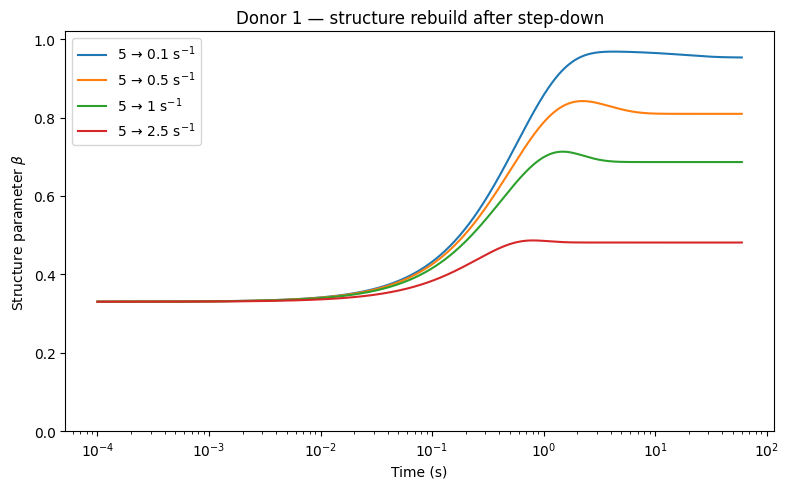

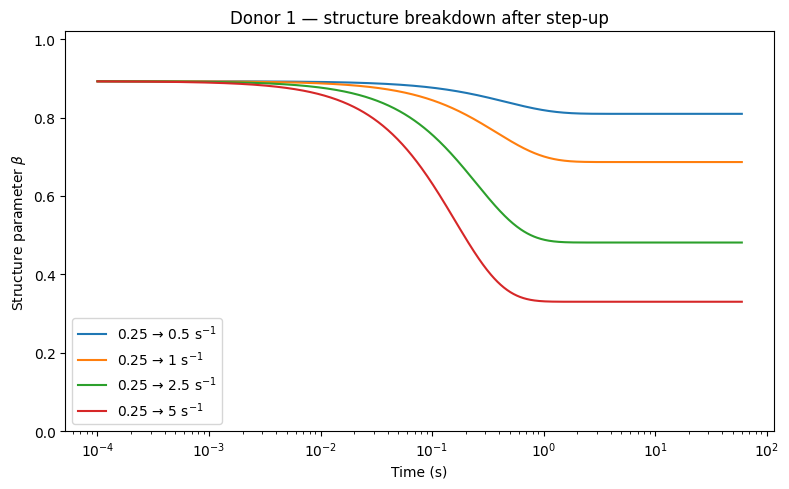

In [87]:

plt.figure(figsize=(8, 5))
for (protocol, initial_rate, final_rate), sim in step_simulations.items():
    if protocol != "step_down":
        continue
    q = sim[sim["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"{initial_rate:g} → {final_rate:g} s$^{{-1}}$")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — structure rebuild after step-down")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for (protocol, initial_rate, final_rate), sim in step_simulations.items():
    if protocol != "step_up":
        continue
    q = sim[sim["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"{initial_rate:g} → {final_rate:g} s$^{{-1}}$")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — structure breakdown after step-up")
plt.legend()
plt.tight_layout()
plt.show()



## 4.5 Validation level E — compare the two steady-stress interpretations

This does **not** decide the ambiguity by itself. It shows how much the two interpretations differ.

Once the Donor 1 steady-state sheet is mapped, use the experimental stress data to calculate \(F_{cost,SS}\) under both versions. The version that reproduces Fig. 1(a) and the reported Donor 1 \(F_{cost,SS}\approx0.0037\) is the stronger candidate.


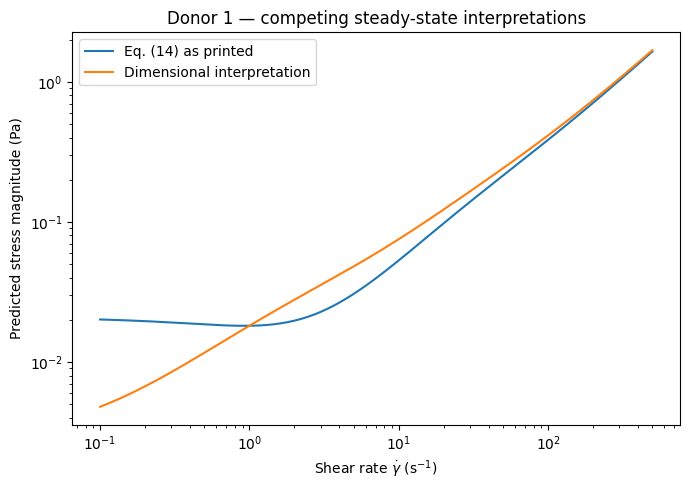

In [88]:

g_grid = np.logspace(-1, np.log10(500), 400)

plt.figure(figsize=(7, 5))
plt.loglog(
    g_grid,
    np.abs(steady_total_stress_as_printed(g_grid, P1)),
    label="Eq. (14) as printed"
)
plt.loglog(
    g_grid,
    np.abs(steady_total_stress_dimensional(g_grid, P1)),
    label="Dimensional interpretation"
)
plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel("Predicted stress magnitude (Pa)")
plt.title("Donor 1 — competing steady-state interpretations")
plt.legend()
plt.tight_layout()
plt.show()


# 5. Paper-native and common evaluation metrics

In [89]:

def fcost_ss_paper(y, f):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)

    mask = np.isfinite(y) & np.isfinite(f) & (np.abs(y) > 1e-15)
    y, f = y[mask], f[mask]

    if len(y) == 0:
        return np.nan

    return np.sqrt(np.sum(((y - f) / y) ** 2)) / len(y)

def fcost_single_trace_paper(y, f):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)

    mask = np.isfinite(y) & np.isfinite(f)
    y, f = y[mask], f[mask]

    if len(y) == 0:
        return np.nan

    return np.sqrt(np.sum((y - f) ** 2)) / len(y)

def fcost_transient_paper(traces):
    values = [fcost_single_trace_paper(y, f) for y, f in traces]
    values = [v for v in values if np.isfinite(v)]
    return np.mean(values) if values else np.nan

def fcost_saos_paper(Gp_data, Gp_model, Gpp_data, Gpp_model):
    Gp_data = np.asarray(Gp_data, dtype=float)
    Gp_model = np.asarray(Gp_model, dtype=float)
    Gpp_data = np.asarray(Gpp_data, dtype=float)
    Gpp_model = np.asarray(Gpp_model, dtype=float)

    n = len(Gp_data)
    if n == 0:
        return np.nan

    return np.sum(
        np.abs(Gp_data - Gp_model)
        + np.abs(Gpp_data - Gpp_model)
    ) / (2 * n)

def paper_rss_like(y, f):
    # Literal printed form: sum(sqrt((y-f)^2)) = sum(abs(residual)).
    r = np.asarray(y, dtype=float) - np.asarray(f, dtype=float)
    r = r[np.isfinite(r)]
    return float(np.sum(np.abs(r)))

def conventional_rss(y, f):
    r = np.asarray(y, dtype=float) - np.asarray(f, dtype=float)
    r = r[np.isfinite(r)]
    return float(np.sum(r**2))

def paper_aic(rss_like, k):
    return 2 * k + 2 * np.log(rss_like)

def paper_bic(rss_like, k, n):
    return 2 * k * np.log(n) + 2 * np.log(rss_like)

def common_metrics(y, f, k=None):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)

    mask = np.isfinite(y) & np.isfinite(f)
    y, f = y[mask], f[mask]

    if len(y) == 0:
        return {}

    residual = y - f
    rss = float(np.sum(residual**2))
    rmse = float(np.sqrt(np.mean(residual**2)))
    mae = float(np.mean(np.abs(residual)))

    data_range = float(np.max(y) - np.min(y))
    nrmse_range = rmse / data_range if data_range > 0 else np.nan

    tss = float(np.sum((y - np.mean(y))**2))
    r2 = 1 - rss / tss if tss > 0 else np.nan

    out = {
        "n": len(y),
        "MAE": mae,
        "RMSE": rmse,
        "NRMSE_range": nrmse_range,
        "R2": r2,
        "RSS_conventional": rss,
        "paper_RSS_like": float(np.sum(np.abs(residual))),
    }

    if k is not None and rss > 0:
        n = len(y)
        out["AIC_common"] = n * np.log(rss / n) + 2 * k
        out["BIC_common"] = n * np.log(rss / n) + k * np.log(n)

    return out



## 5.1 Compare a steady-state dataset directly with the paper

After you identify the correct Donor 1 steady-state columns, call:

```python
comparison = compare_steady_state_to_paper(
    shear_rate=steady_df["Shear rate"],
    measured_stress=steady_df["Stress"],
    donor=1
)
display(comparison["summary"])
```

This evaluates **both Eq. (14) interpretations** side-by-side.


In [90]:

def compare_steady_state_to_paper(
    shear_rate,
    measured_stress,
    donor=1,
    paper_target=None,
):
    p = params_for_donor(donor)

    shear_rate = np.asarray(shear_rate, dtype=float)
    measured_stress = np.asarray(measured_stress, dtype=float)

    pred_printed = steady_total_stress_as_printed(shear_rate, p)
    pred_dimensional = steady_total_stress_dimensional(shear_rate, p)

    if paper_target is None:
        row = reported_params.loc[reported_params["Donor"] == donor].iloc[0]
        paper_target = float(row["Fcost_SS"])

    rows = []

    for label, prediction in [
        ("as_printed", pred_printed),
        ("dimensional_interpretation", pred_dimensional),
    ]:
        fcost = fcost_ss_paper(measured_stress, prediction)
        metrics = common_metrics(measured_stress, prediction)

        rows.append({
            "variant": label,
            "paper_target_Fcost_SS": paper_target,
            "calculated_Fcost_SS": fcost,
            "abs_difference_from_paper": abs(fcost - paper_target),
            "MAE": metrics.get("MAE"),
            "RMSE": metrics.get("RMSE"),
            "R2": metrics.get("R2"),
            "RSS_conventional": metrics.get("RSS_conventional"),
        })

    return {
        "summary": pd.DataFrame(rows).sort_values("abs_difference_from_paper"),
        "prediction_as_printed": pred_printed,
        "prediction_dimensional": pred_dimensional,
    }

def plot_steady_state_overlay(shear_rate, measured_stress, donor=1):
    result = compare_steady_state_to_paper(shear_rate, measured_stress, donor=donor)

    shear_rate = np.asarray(shear_rate, dtype=float)
    measured_stress = np.asarray(measured_stress, dtype=float)

    order = np.argsort(shear_rate)

    plt.figure(figsize=(7, 5))
    plt.loglog(shear_rate, np.abs(measured_stress), "o", label="Experimental data")
    plt.loglog(
        shear_rate[order],
        np.abs(result["prediction_as_printed"][order]),
        label="Eq. (14) as printed"
    )
    plt.loglog(
        shear_rate[order],
        np.abs(result["prediction_dimensional"][order]),
        label="Dimensional interpretation"
    )
    plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
    plt.ylabel("Stress magnitude (Pa)")
    plt.title(f"Donor {donor} — experimental vs reconstructed steady-state stress")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return result["summary"]


Donor 1 steady-state Fcost comparison


,variant,paper_target_Fcost_SS,calculated_Fcost_SS,abs_difference_from_paper,MAE,RMSE,R2,RSS_conventional
0,dimensional_interpretation,0.0037,0.042555,0.038855,0.003743,0.005924,0.999901,0.000561
1,as_printed,0.0037,0.388943,0.385243,0.017532,0.019285,0.998949,0.005951



Paper target Fcost_SS = 0.0037


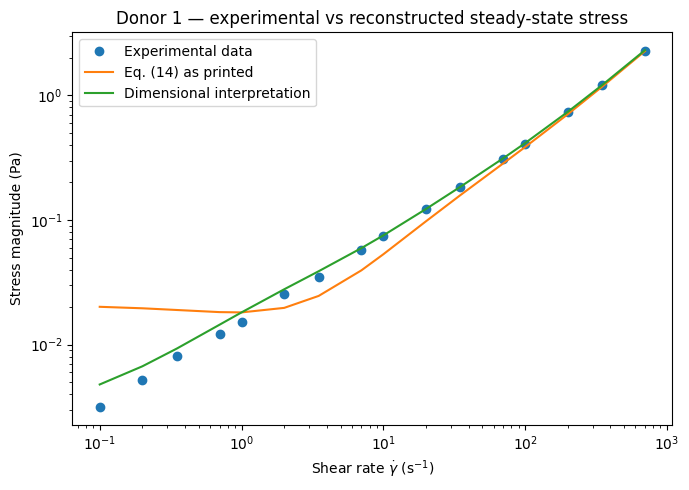

Donor 1 steady-state Fcost comparison


,variant,paper_target_Fcost_SS,calculated_Fcost_SS,abs_difference_from_paper,MAE,RMSE,R2,RSS_conventional
0,dimensional_interpretation,0.0037,0.098144,0.094444,0.013225,0.021763,0.998605,0.007578
1,as_printed,0.0037,0.609348,0.605648,0.012690,0.014658,0.999367,0.003438



Paper target Fcost_SS = 0.0037


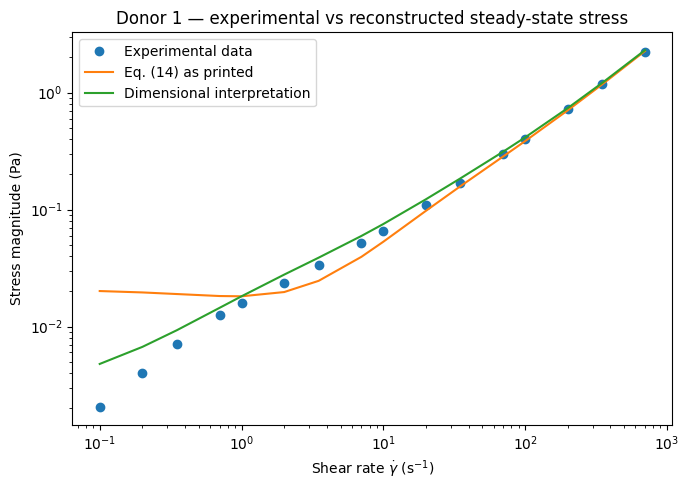

In [ ]:
# Automatic Donor 1 steady-state paper cross-check.
# This uses the author's reported Donor 1 parameters; it does NOT refit them.

STEADY_COMPARISON = None
STEADY_DATA = STEADY_DATA_DEC17 

if isinstance(STEADY_DATA, pd.DataFrame) and not STEADY_DATA.empty:
    steady_result = compare_steady_state_to_paper(
        shear_rate=STEADY_DATA["shear_rate"],
        measured_stress=STEADY_DATA["stress"],
        donor=1,
    )

    STEADY_COMPARISON = steady_result["summary"].reset_index(drop=True)

    print("Donor 1 steady-state Fcost comparison")
    display(STEADY_COMPARISON)

    print(
        "\nPaper target Fcost_SS =",
        PAPER_TARGETS_DONOR1["Fcost_SS"],
    )

    plot_steady_state_overlay(
        shear_rate=STEADY_DATA["shear_rate"],
        measured_stress=STEADY_DATA["stress"],
        donor=1,
    )
else:
    print("PENDING: Steady-state data are not available.")

STEADY_DATA = STEADY_DATA_JUN18
if isinstance(STEADY_DATA, pd.DataFrame) and not STEADY_DATA.empty:
    steady_result = compare_steady_state_to_paper(
        shear_rate=STEADY_DATA["shear_rate"],
        measured_stress=STEADY_DATA["stress"],
        donor=1,
    )

    STEADY_COMPARISON = steady_result["summary"].reset_index(drop=True)

    print("Donor JUN18 steady-state Fcost comparison")
    display(STEADY_COMPARISON)

    print(
        "\nPaper target Fcost_SS =",
        PAPER_TARGETS_DONOR1["Fcost_SS"],
    )

    plot_steady_state_overlay(
        shear_rate=STEADY_DATA["shear_rate"],
        measured_stress=STEADY_DATA["stress"],
        donor=1,
    )
else:
    print("PENDING: Steady-state data are not available.")    



## 5.2 Generic paper-metric cross-check

Use this when a full stress prediction becomes available.

A result close to the paper target is stronger evidence that:

- the correct raw data were selected,
- the same preprocessing was used,
- the equation interpretation is correct,
- the initial conditions are compatible,
- the model prediction is being evaluated using the same cost definition.


In [92]:

def compare_metric_to_paper(name, calculated, target, tolerance):
    return pd.DataFrame([
        make_validation_row(
            "Paper-metric cross-check",
            name,
            calculated,
            target,
            tolerance,
            "Tolerance should be justified from parameter/data precision."
        )
    ])

# Example once Donor 1 steady-state predictions exist:
# compare_metric_to_paper(
#     "Donor 1 Fcost_SS",
#     calculated=your_fcost,
#     target=PAPER_TARGETS_DONOR1["Fcost_SS"],
#     tolerance=5e-4,
# )


# 6. Oscillatory validation — SAOS / LAOS / UD-LAOS


For oscillatory shear the paper uses

\[
\gamma(t)=\gamma_0\sin(\omega t),
\qquad
\dot{\gamma}(t)=\gamma_0\omega\cos(\omega t)
\]

for LAOS, and adds a positive steady component for UD-LAOS.

The stress harmonic representation is

\[
\tau_{yx}(t)
=
\gamma_0
\sum_{i,\mathrm{odd}}
\left[
G_i'\sin(i\omega t)
+
G_i''\cos(i\omega t)
\right].
\]

The relative third harmonic is

\[
\frac{I_3}{I_1}
=
\sqrt{
\frac{G_3'^2+G_3''^2}
{G_1'^2+G_1''^2}
}.
\]

The synthetic unit test below checks that our harmonic extraction itself is working before it is applied to blood data.


In [93]:

def fit_odd_harmonics(t, stress, gamma0, omega, harmonics=(1, 3, 5)):
    t = np.asarray(t, dtype=float)
    stress = np.asarray(stress, dtype=float)

    mask = np.isfinite(t) & np.isfinite(stress)
    t, stress = t[mask], stress[mask]

    columns = []
    names = []

    for n in harmonics:
        columns.append(gamma0 * np.sin(n * omega * t))
        names.append((n, "Gp"))
        columns.append(gamma0 * np.cos(n * omega * t))
        names.append((n, "Gpp"))

    X = np.column_stack(columns)
    coef, *_ = np.linalg.lstsq(X, stress, rcond=None)

    return {name: float(value) for name, value in zip(names, coef)}

def harmonic_intensity_ratio(harmonic_fit, numerator=3, denominator=1):
    Gp_num = harmonic_fit.get((numerator, "Gp"), 0.0)
    Gpp_num = harmonic_fit.get((numerator, "Gpp"), 0.0)
    Gp_den = harmonic_fit.get((denominator, "Gp"), 0.0)
    Gpp_den = harmonic_fit.get((denominator, "Gpp"), 0.0)

    numerator_intensity = Gp_num**2 + Gpp_num**2
    denominator_intensity = Gp_den**2 + Gpp_den**2

    return (
        np.sqrt(numerator_intensity / denominator_intensity)
        if denominator_intensity > 0
        else np.nan
    )

# Synthetic signal with known coefficients:
# G1' = 2, G1'' = 1, G3' = 0.2, G3'' = 0.
t_test = np.linspace(0, 2 * np.pi, 1000, endpoint=False)
stress_test = (
    2.0 * np.sin(t_test)
    + 1.0 * np.cos(t_test)
    + 0.2 * np.sin(3 * t_test)
)

harmonic_test = fit_odd_harmonics(
    t_test,
    stress_test,
    gamma0=1.0,
    omega=1.0,
)

expected_I3_I1 = np.sqrt(0.2**2 / (2.0**2 + 1.0**2))
calculated_I3_I1 = harmonic_intensity_ratio(harmonic_test)

harmonic_validation = pd.DataFrame([
    make_validation_row(
        "Oscillatory unit test",
        "G1'",
        harmonic_test[(1, "Gp")],
        2.0,
        1e-10,
    ),
    make_validation_row(
        "Oscillatory unit test",
        "G1''",
        harmonic_test[(1, "Gpp")],
        1.0,
        1e-10,
    ),
    make_validation_row(
        "Oscillatory unit test",
        "G3'",
        harmonic_test[(3, "Gp")],
        0.2,
        1e-10,
    ),
    make_validation_row(
        "Oscillatory unit test",
        "I3/I1",
        calculated_I3_I1,
        expected_I3_I1,
        1e-10,
    ),
])

display(harmonic_validation)


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,Oscillatory unit test,G1',2.000000,2.000000,4.440892e-16,1.000000e-10,PASS,
1,Oscillatory unit test,G1'',1.000000,1.000000,6.661338e-16,1.000000e-10,PASS,
2,Oscillatory unit test,G3',0.200000,0.200000,4.163336e-16,1.000000e-10,PASS,
3,Oscillatory unit test,I3/I1,0.089443,0.089443,1.942890e-16,1.000000e-10,PASS,


# 7. Steady-state fitting scaffold


The paper uses a global stochastic **parallel-tempering** optimizer.

The function below uses SciPy `least_squares` as a transparent Python fitting scaffold. This reproduces the **objective structure**, but it is **not the same optimizer** as the authors used.

For research reporting, label results accordingly.


In [94]:

def fit_steady_state_example(
    shear_rate,
    stress,
    initial=P1,
    use_dimensional_variant=True,
):
    shear_rate = np.asarray(shear_rate, dtype=float)
    stress = np.asarray(stress, dtype=float)

    names = [
        "eta0", "lambda1", "lambda2", "alpha",
        "tr1", "tr2", "muR", "tau_y0", "m"
    ]

    x0 = np.array([getattr(initial, name) for name in names], dtype=float)

    lower = np.array([
        1e-5, 1e-4, 1e-5, 1e-6,
        1e-4, 1e-5, 1e-5, 0.0, 0.2
    ])

    upper = np.array([
        0.05, 5.0, 5.0, 0.99,
        10.0, 10.0, 1.0, 0.1, 4.0
    ])

    def unpack(x):
        p = EthixoGiesekusParams(**asdict(initial))

        for name, value in zip(names, x):
            setattr(p, name, float(value))

        frac_s = initial.eta_s / max(initial.eta0, 1e-12)
        p.eta_s = p.eta0 * frac_s
        p.eta_p = p.eta0 - p.eta_s

        return p

    predictor = (
        steady_total_stress_dimensional
        if use_dimensional_variant
        else steady_total_stress_as_printed
    )

    def residuals(x):
        p = unpack(x)
        prediction = predictor(shear_rate, p)
        denom = np.where(np.abs(stress) > 1e-12, stress, 1e-12)
        return (stress - prediction) / denom

    start = time.perf_counter()

    result = least_squares(
        residuals,
        x0,
        bounds=(lower, upper),
    )

    runtime = time.perf_counter() - start

    p_best = unpack(result.x)
    prediction = predictor(shear_rate, p_best)

    return {
        "params": p_best,
        "prediction": prediction,
        "Fcost_SS_paper": fcost_ss_paper(stress, prediction),
        "common_metrics": common_metrics(stress, prediction, k=len(names)),
        "runtime_s": runtime,
        "optimizer_result": result,
    }


# 8. Physiological correlations

,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R
HCT_percent,0.519,0.896,0.391,-0.618,-0.755,0.198,-0.542,-0.659,0.062,0.246,-0.167,-0.604,0.299
Fibrinogen_mg_dl,0.217,-0.243,0.309,0.768,0.787,-0.682,-0.082,0.164,-0.003,-0.743,0.870,0.912,0.619
Total_cholesterol_mg_ml,0.253,0.275,0.225,0.129,0.009,-0.226,0.413,-0.430,0.764,0.925,-0.176,-0.516,-0.044
Triglycerides_mg_ml,-0.000,-0.643,0.140,0.707,0.762,-0.406,0.341,0.285,-0.021,-0.627,0.547,0.782,0.292
HDL_mg_ml,0.211,0.512,0.131,-0.047,-0.153,-0.183,0.052,-0.384,0.581,0.844,-0.157,-0.528,-0.035
LDL_mg_ml,0.256,0.217,0.238,0.123,0.000,-0.186,0.500,-0.448,0.783,0.944,-0.223,-0.547,-0.068


,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R
HCT_percent,0.370,0.039,0.515,0.266,0.140,0.750,0.346,0.226,0.921,0.689,0.788,0.281,0.625
Fibrinogen_mg_dl,0.725,0.693,0.612,0.130,0.114,0.205,0.895,0.792,0.997,0.150,0.055,0.031,0.266
Total_cholesterol_mg_ml,0.681,0.655,0.716,0.837,0.989,0.715,0.489,0.470,0.133,0.024,0.777,0.373,0.944
Triglycerides_mg_ml,0.999,0.241,0.823,0.182,0.135,0.497,0.575,0.642,0.973,0.258,0.340,0.118,0.633
HDL_mg_ml,0.734,0.378,0.834,0.940,0.806,0.768,0.934,0.524,0.304,0.072,0.801,0.360,0.955
LDL_mg_ml,0.677,0.726,0.699,0.844,1.000,0.765,0.391,0.449,0.117,0.016,0.719,0.341,0.914


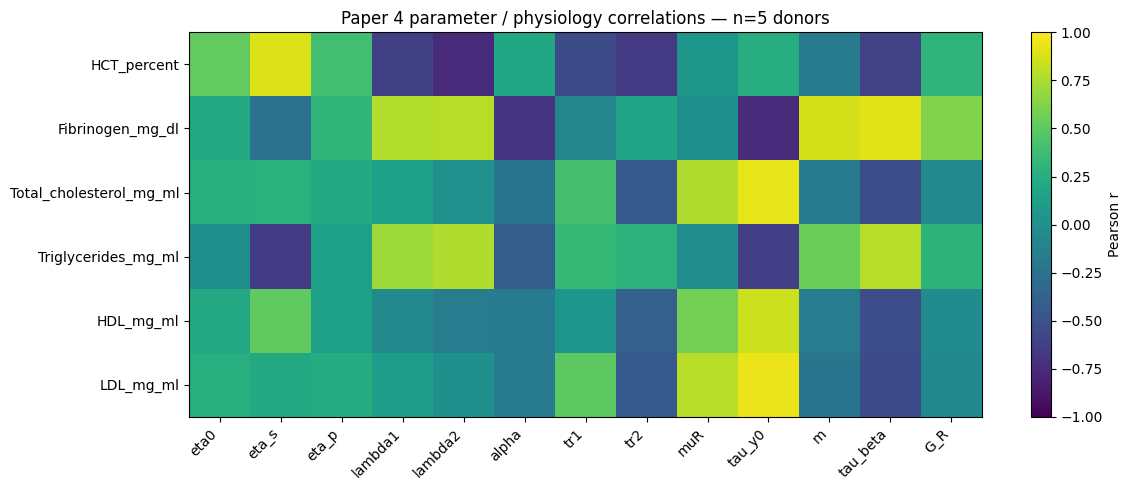

In [95]:

model_parameter_cols = [
    "eta0", "eta_s", "eta_p", "lambda1", "lambda2", "alpha",
    "tr1", "tr2", "muR", "tau_y0", "m", "tau_beta", "G_R"
]

physiology_cols = [
    "HCT_percent",
    "Fibrinogen_mg_dl",
    "Total_cholesterol_mg_ml",
    "Triglycerides_mg_ml",
    "HDL_mg_ml",
    "LDL_mg_ml",
]

master = physiology.merge(
    reported_params[["Donor"] + model_parameter_cols],
    on="Donor",
    how="inner",
)

corr = pd.DataFrame(
    index=physiology_cols,
    columns=model_parameter_cols,
    dtype=float,
)

pvals = corr.copy()

for phys in physiology_cols:
    for parameter in model_parameter_cols:
        r, p_value = pearsonr(master[phys], master[parameter])
        corr.loc[phys, parameter] = r
        pvals.loc[phys, parameter] = p_value

display(corr.round(3))
display(pvals.round(3))

plt.figure(figsize=(12, 5))
image = plt.imshow(corr.astype(float), aspect="auto", vmin=-1, vmax=1)
plt.colorbar(image, label="Pearson r")
plt.xticks(
    range(len(model_parameter_cols)),
    model_parameter_cols,
    rotation=45,
    ha="right",
)
plt.yticks(range(len(physiology_cols)), physiology_cols)
plt.title("Paper 4 parameter / physiology correlations — n=5 donors")
plt.tight_layout()
plt.show()



**Interpret these correlations cautiously.** With only five donors, large correlation coefficients can occur with considerable uncertainty. Always report the coefficient together with the p-value and sample size.


# 9. Paper-reported peer-model benchmark

,model,Fcost_SS,k_SS,AIC_SS,BIC_SS,Fcost_trans,k_trans,AIC_trans,BIC_trans,Fcost_LAOS,Fcost_UDLAOS,Fcost_SAOS,Fcost_total
0,ethixo-Giesekus,0.01210,11,14.565,53.562,0.00070,13,20.53,149.649,0.00085,0.00085,0.00251,0.00123
1,ethixo-Convected Maxwell,0.01601,6,8.430,33.250,0.00051,10,13.45,112.770,0.00106,0.00119,0.00309,0.00146
2,Corotational Jeffreys,0.00844,8,7.750,36.110,0.00052,11,15.51,124.770,0.00060,0.00082,0.00687,0.00220
3,Oldroyd-4,0.01097,9,10.820,42.730,0.00076,12,19.10,138.290,0.00133,0.00243,0.00298,0.00187
4,mHAWB,0.00619,9,8.630,40.540,0.00052,12,17.52,136.710,0.00066,0.00080,0.00169,0.00092


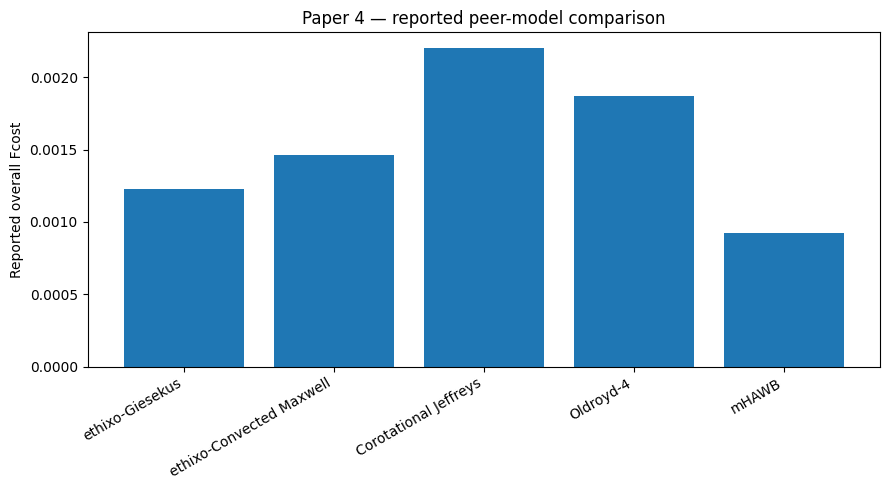

In [96]:

paper4_model_benchmark = pd.DataFrame([
    {
        "model": "ethixo-Giesekus",
        "Fcost_SS": 0.0121,
        "k_SS": 11,
        "AIC_SS": 14.565,
        "BIC_SS": 53.562,
        "Fcost_trans": 0.00070,
        "k_trans": 13,
        "AIC_trans": 20.530,
        "BIC_trans": 149.649,
        "Fcost_LAOS": 0.00085,
        "Fcost_UDLAOS": 0.00085,
        "Fcost_SAOS": 0.00251,
        "Fcost_total": 0.00123,
    },
    {
        "model": "ethixo-Convected Maxwell",
        "Fcost_SS": 0.01601,
        "k_SS": 6,
        "AIC_SS": 8.43,
        "BIC_SS": 33.25,
        "Fcost_trans": 0.00051,
        "k_trans": 10,
        "AIC_trans": 13.45,
        "BIC_trans": 112.77,
        "Fcost_LAOS": 0.00106,
        "Fcost_UDLAOS": 0.00119,
        "Fcost_SAOS": 0.00309,
        "Fcost_total": 0.00146,
    },
    {
        "model": "Corotational Jeffreys",
        "Fcost_SS": 0.00844,
        "k_SS": 8,
        "AIC_SS": 7.75,
        "BIC_SS": 36.11,
        "Fcost_trans": 0.00052,
        "k_trans": 11,
        "AIC_trans": 15.51,
        "BIC_trans": 124.77,
        "Fcost_LAOS": 0.00060,
        "Fcost_UDLAOS": 0.00082,
        "Fcost_SAOS": 0.00687,
        "Fcost_total": 0.00220,
    },
    {
        "model": "Oldroyd-4",
        "Fcost_SS": 0.01097,
        "k_SS": 9,
        "AIC_SS": 10.82,
        "BIC_SS": 42.73,
        "Fcost_trans": 0.00076,
        "k_trans": 12,
        "AIC_trans": 19.10,
        "BIC_trans": 138.29,
        "Fcost_LAOS": 0.00133,
        "Fcost_UDLAOS": 0.00243,
        "Fcost_SAOS": 0.00298,
        "Fcost_total": 0.00187,
    },
    {
        "model": "mHAWB",
        "Fcost_SS": 0.00619,
        "k_SS": 9,
        "AIC_SS": 8.63,
        "BIC_SS": 40.54,
        "Fcost_trans": 0.00052,
        "k_trans": 12,
        "AIC_trans": 17.52,
        "BIC_trans": 136.71,
        "Fcost_LAOS": 0.00066,
        "Fcost_UDLAOS": 0.00080,
        "Fcost_SAOS": 0.00169,
        "Fcost_total": 0.00092,
    },
])

display(paper4_model_benchmark)

plt.figure(figsize=(9, 5))
plt.bar(
    paper4_model_benchmark["model"],
    paper4_model_benchmark["Fcost_total"],
)
plt.ylabel("Reported overall Fcost")
plt.title("Paper 4 — reported peer-model comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 10. Standardized cross-paper result format

In [97]:

STANDARD_RESULT_COLUMNS = [
    "paper_id",
    "paper_title_short",
    "model",
    "donor",
    "dataset",
    "experiment",
    "fit_or_prediction",
    "n_points",
    "n_fitted_parameters",
    "paper_metric_name",
    "paper_metric_value",
    "paper_metric_target",
    "paper_metric_abs_difference",
    "MAE",
    "RMSE",
    "NRMSE_range",
    "R2",
    "RSS_conventional",
    "AIC_common",
    "BIC_common",
    "I3_I1_data",
    "I3_I1_model",
    "runtime_s",
    "validation_status",
    "notes",
]

def make_result_row(
    model,
    donor,
    dataset,
    experiment,
    y,
    prediction,
    n_fitted_parameters,
    paper_metric_name=None,
    paper_metric_value=np.nan,
    paper_metric_target=np.nan,
    fit_or_prediction="prediction",
    runtime_s=np.nan,
    validation_status="UNASSESSED",
    notes="",
):
    metrics = common_metrics(y, prediction, k=n_fitted_parameters)

    paper_diff = (
        abs(paper_metric_value - paper_metric_target)
        if np.isfinite(paper_metric_value) and np.isfinite(paper_metric_target)
        else np.nan
    )

    return {
        "paper_id": 4,
        "paper_title_short": "Integration of thixotropy into Giesekus",
        "model": model,
        "donor": donor,
        "dataset": dataset,
        "experiment": experiment,
        "fit_or_prediction": fit_or_prediction,
        "n_points": metrics.get("n", np.nan),
        "n_fitted_parameters": n_fitted_parameters,
        "paper_metric_name": paper_metric_name,
        "paper_metric_value": paper_metric_value,
        "paper_metric_target": paper_metric_target,
        "paper_metric_abs_difference": paper_diff,
        "MAE": metrics.get("MAE", np.nan),
        "RMSE": metrics.get("RMSE", np.nan),
        "NRMSE_range": metrics.get("NRMSE_range", np.nan),
        "R2": metrics.get("R2", np.nan),
        "RSS_conventional": metrics.get("RSS_conventional", np.nan),
        "AIC_common": metrics.get("AIC_common", np.nan),
        "BIC_common": metrics.get("BIC_common", np.nan),
        "I3_I1_data": np.nan,
        "I3_I1_model": np.nan,
        "runtime_s": runtime_s,
        "validation_status": validation_status,
        "notes": notes,
    }

comparison_results = pd.DataFrame(columns=STANDARD_RESULT_COLUMNS)
display(comparison_results)


,paper_id,paper_title_short,model,donor,dataset,experiment,fit_or_prediction,n_points,n_fitted_parameters,paper_metric_name,paper_metric_value,paper_metric_target,paper_metric_abs_difference,MAE,RMSE,NRMSE_range,R2,RSS_conventional,AIC_common,BIC_common,I3_I1_data,I3_I1_model,runtime_s,validation_status,notes


# 11. One-page validation dashboard

In [98]:

def build_validation_dashboard():
    rows = []

    # Parameter checks
    rows.extend(validate_parameter_identities(P1).to_dict("records"))

    # Eq. 13 deterministic checkpoints
    max_eq13_error = float(EQ13_CHECKPOINTS_DONOR1["abs_error"].max())
    rows.append(make_validation_row(
        "B — Eq. 13",
        "All Donor 1 beta_ss numerical checkpoints",
        max_eq13_error,
        0.0,
        1e-9,
        "Calculated value is the maximum absolute checkpoint error."
    ))

    # Physical checks
    rows.extend(physical_limit_validation.to_dict("records"))

    # Step endpoint checks
    max_start_error = float(step_validation["start_abs_error"].max())
    max_end_error = float(step_validation["end_abs_error"].max())
    direction_pass = bool(step_validation["direction_correct"].all())

    rows.append(make_validation_row(
        "D — transient structure",
        "Maximum step initial-beta error",
        max_start_error,
        0.0,
        1e-8,
    ))

    rows.append(make_validation_row(
        "D — transient structure",
        "Maximum long-time beta endpoint error",
        max_end_error,
        0.0,
        0.01,
    ))

    rows.append({
        "stage": "D — transient structure",
        "check": "All step directions physically correct",
        "calculated": direction_pass,
        "paper_or_expected_target": True,
        "absolute_difference": np.nan,
        "tolerance": np.nan,
        "status": "PASS" if direction_pass else "FAIL",
        "notes": "Step-down rebuilds; step-up breaks structure.",
    })

    # Oscillatory unit tests
    rows.extend(harmonic_validation.to_dict("records"))

    # Donor 1 steady-state paper cross-check.
    if isinstance(STEADY_COMPARISON, pd.DataFrame) and not STEADY_COMPARISON.empty:
        best_steady = STEADY_COMPARISON.sort_values(
            "abs_difference_from_paper"
        ).iloc[0]

        steady_diff = float(best_steady["abs_difference_from_paper"])
        steady_tol = 5e-4

        rows.append({
            "stage": "E — steady stress",
            "check": "Donor 1 Fcost_SS approximately 0.0037",
            "calculated": float(best_steady["calculated_Fcost_SS"]),
            "paper_or_expected_target": PAPER_TARGETS_DONOR1["Fcost_SS"],
            "absolute_difference": steady_diff,
            "tolerance": steady_tol,
            "status": "PASS" if steady_diff <= steady_tol else "CHECK",
            "notes": (
                "Mapped automatically from DEC17 SS SAOS t=0 h. "
                f"Best Eq. (14) variant: {best_steady['variant']}. "
                "CHECK means the data are mapped but the reconstructed stress "
                "equation does not yet match the paper target closely enough."
            ),
        })
    else:
        rows.append({
            "stage": "E — steady stress",
            "check": "Donor 1 Fcost_SS approximately 0.0037",
            "calculated": np.nan,
            "paper_or_expected_target": PAPER_TARGETS_DONOR1["Fcost_SS"],
            "absolute_difference": np.nan,
            "tolerance": 5e-4,
            "status": "PENDING",
            "notes": "DEC17 steady-state data were not available/mapped.",
        })

    rows.append({
        "stage": "F — transient stress",
        "check": "Donor 1 Fcost_trans approximately 0.00056",
        "calculated": np.nan,
        "paper_or_expected_target": PAPER_TARGETS_DONOR1["Fcost_trans"],
        "absolute_difference": np.nan,
        "tolerance": 1e-4,
        "status": "PENDING",
        "notes": "Requires validated full transient Giesekus tensor + experimental step traces.",
    })

    return pd.DataFrame(rows)

validation_dashboard = build_validation_dashboard()
display(validation_dashboard)

print("\nStatus counts:")
display(validation_dashboard["status"].value_counts().rename_axis("status").to_frame("count"))


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,A — parameters,eta0 = eta_s + eta_p,0.0051,0.0051,0.000000e+00,5.000000e-05,PASS,Uses rounded values printed in the paper.
1,A — parameters,lambda2 relation,0.016412,0.0164,1.176471e-05,5.000000e-04,PASS,Small discrepancy is acceptable because the pa...
2,B — Eq. 13,All Donor 1 beta_ss numerical checkpoints,0.0,0.0,4.666362e-11,1.000000e-09,PASS,Calculated value is the maximum absolute check...
3,C — physical limits,beta_ss(0) = 1,1.0,1.0,0.000000e+00,1.000000e-12,PASS,At zero shear the steady structure should be f...
4,C — physical limits,beta_ss(1e6) approximately 0,0.000224,0.0,2.235281e-04,1.000000e-04,FAIL,At very high shear the structure should approa...
5,C — physical limits,beta_ss decreases as shear increases,1.0,1.0,NaN,NaN,PASS,Qualitative physical behavior expected for rou...
6,D — transient structure,Maximum step initial-beta error,0.0,0.0,1.110223e-16,1.000000e-08,PASS,
7,D — transient structure,Maximum long-time beta endpoint error,0.000115,0.0,1.153583e-04,1.000000e-02,PASS,
8,D — transient structure,All step directions physically correct,True,True,NaN,NaN,PASS,Step-down rebuilds; step-up breaks structure.
9,Oscillatory unit test,G1',2.0,2.0,4.440892e-16,1.000000e-10,PASS,



Status counts:


,count
status,
PASS,12
FAIL,1
CHECK,1
PENDING,1



# 12. Interpretation of the validation levels

Use the following language when documenting results:

### Level 1 — Equation reproduced
The Python function returns the correct deterministic values and physical limits for the published equation.

### Level 2 — Structure dynamics reproduced
Using the paper's reported parameters, the Python ODE reproduces the expected step-up/down direction and terminal structure values.

### Level 3 — Paper stress result reproduced
Using the same experimental data and published parameters, the Python stress prediction reproduces the paper's curves and reported \(F_{cost}\) within a stated tolerance.

### Level 4 — Prediction reproduced
Without refitting to the prediction experiment, the implementation reproduces SAOS / LAOS / UD-LAOS behavior and harmonic metrics.

### Level 5 — Independent Python fit reproduced
A Python optimizer recovers parameter values and model performance comparable to the paper.

Do not call the implementation an **exact reproduction** until the relevant Level 3–4 checks pass.


# 13. Export reproducibility records

In [99]:

physiology.to_csv(
    RESULTS_ROOT / "paper4_physiology.csv",
    index=False,
)

reported_params.to_csv(
    RESULTS_ROOT / "paper4_reported_parameters.csv",
    index=False,
)

paper4_model_benchmark.to_csv(
    RESULTS_ROOT / "paper4_reported_model_benchmark.csv",
    index=False,
)

EQ13_CHECKPOINTS_DONOR1.to_csv(
    RESULTS_ROOT / "paper4_eq13_validation.csv",
    index=False,
)

step_validation.to_csv(
    RESULTS_ROOT / "paper4_step_structure_validation.csv",
    index=False,
)

validation_dashboard.to_csv(
    RESULTS_ROOT / "paper4_validation_dashboard.csv",
    index=False,
)

if isinstance(STEADY_DATA, pd.DataFrame) and not STEADY_DATA.empty:
    STEADY_DATA.to_csv(
        RESULTS_ROOT / "paper4_dec17_donor1_steady_state.csv",
        index=False,
    )

if isinstance(STEADY_COMPARISON, pd.DataFrame) and not STEADY_COMPARISON.empty:
    STEADY_COMPARISON.to_csv(
        RESULTS_ROOT / "paper4_dec17_donor1_fcost_ss_comparison.csv",
        index=False,
    )

if len(comparison_results):
    comparison_results.to_csv(
        RESULTS_ROOT / "paper4_standardized_model_results.csv",
        index=False,
    )

print("Validation and comparison outputs saved to:")
print(RESULTS_ROOT)


Validation and comparison outputs saved to:
c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\results\paper4


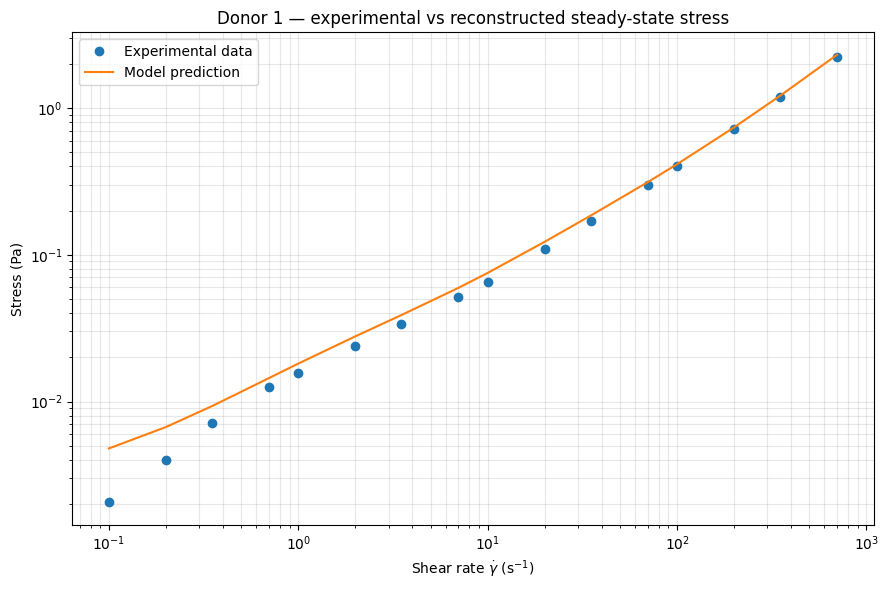

Saved: results\paper4\plots\donor1_steady_state_fit.png


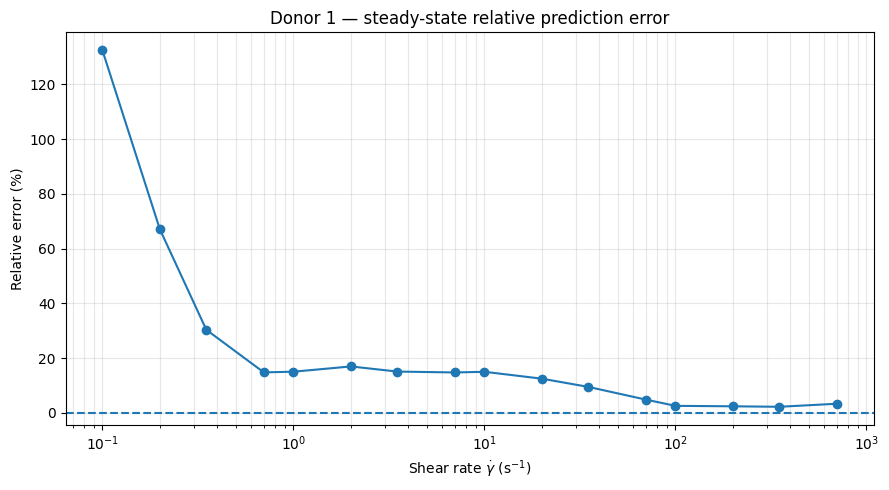

Saved: results\paper4\plots\donor1_steady_state_relative_error.png


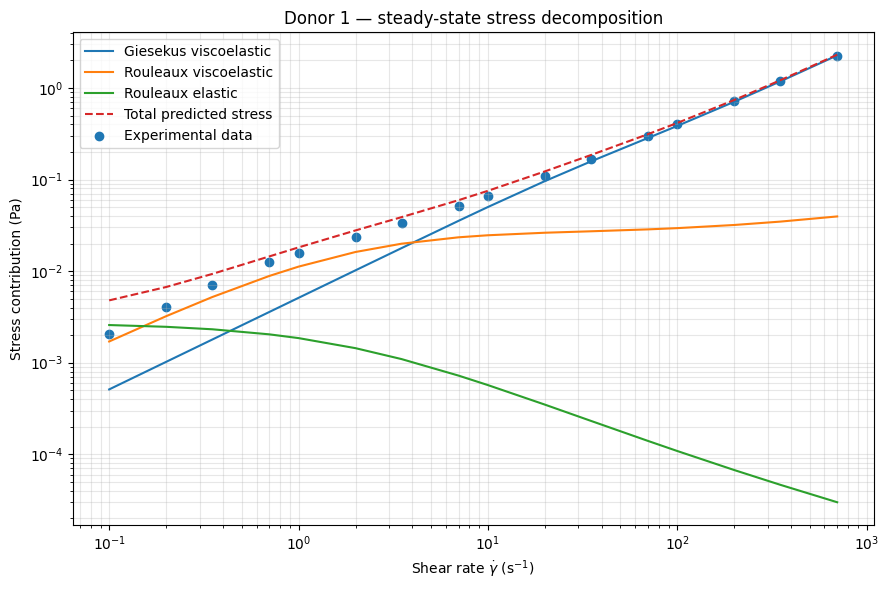

Saved: results\paper4\plots\donor1_steady_state_components.png


In [100]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Output folder
# --------------------------------------------------

PLOT_DIR = Path("./results/paper4/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# Prepare Donor 1 steady-state predictions
# --------------------------------------------------

gdot = STEADY_DATA["shear_rate"].to_numpy(dtype=float)
measured = STEADY_DATA["stress"].to_numpy(dtype=float)

order = np.argsort(gdot)

# Steady structure
beta = beta_ss(gdot, P1)

# Giesekus viscoelastic contribution
tau_ve = tau_ve_ss(gdot, P1)

# Rouleaux viscoelastic contribution
tau_r_ve = (
    P1.muR
    * beta**P1.m
    * gdot
)

# Rouleaux elastic contribution
tau_r_e = (
    P1.tau_y0
    * beta
)

# Dimensionally consistent total stress
predicted = (
    tau_ve
    + tau_r_ve
    + tau_r_e
)


# ==================================================
# Figure 1 — Experimental vs predicted stress
# ==================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.loglog(
    gdot,
    measured,
    "o",
    label="Experimental data"
)

ax.loglog(
    gdot[order],
    predicted[order],
    label="Model prediction"
)

ax.set_xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
ax.set_ylabel("Stress (Pa)")
ax.set_title(
    "Donor 1 — experimental vs reconstructed steady-state stress"
)

ax.legend()
ax.grid(True, which="both", alpha=0.3)

fig.tight_layout()

save_path = PLOT_DIR / "donor1_steady_state_fit.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", save_path)


# ==================================================
# Figure 2 — Relative prediction error
# ==================================================

relative_error = (
    (predicted - measured)
    / measured
    * 100
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.semilogx(
    gdot,
    relative_error,
    "o-"
)

ax.axhline(
    0,
    linestyle="--"
)

ax.set_xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
ax.set_ylabel("Relative error (%)")
ax.set_title(
    "Donor 1 — steady-state relative prediction error"
)

ax.grid(True, which="both", alpha=0.3)

fig.tight_layout()

save_path = PLOT_DIR / "donor1_steady_state_relative_error.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", save_path)


# ==================================================
# Figure 3 — Stress component decomposition
# ==================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.loglog(
    gdot[order],
    tau_ve[order],
    label="Giesekus viscoelastic"
)

ax.loglog(
    gdot[order],
    tau_r_ve[order],
    label="Rouleaux viscoelastic"
)

ax.loglog(
    gdot[order],
    tau_r_e[order],
    label="Rouleaux elastic"
)

ax.loglog(
    gdot[order],
    predicted[order],
    linestyle="--",
    label="Total predicted stress"
)

ax.scatter(
    gdot,
    measured,
    label="Experimental data"
)

ax.set_xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
ax.set_ylabel("Stress contribution (Pa)")
ax.set_title(
    "Donor 1 — steady-state stress decomposition"
)

ax.legend()
ax.grid(True, which="both", alpha=0.3)

fig.tight_layout()

save_path = PLOT_DIR / "donor1_steady_state_components.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", save_path)


# 14. Next concrete task with your local workbooks

The next step is **not** to fit all parameters immediately.

First:

1. inspect the loaded sheet names,
2. identify the Donor 1 steady-state sheet,
3. determine the actual header row,
4. identify the exact shear-rate and stress columns,
5. tidy that sheet,
6. run `plot_steady_state_overlay(...)`,
7. compare both Eq. (14) interpretations,
8. check which version gets closest to the paper's \(F_{cost,SS}=0.0037\).

Then repeat the mapping process for the four step-down and four step-up traces.

Only after those checks should the full transient Giesekus tensor and parameter fitting be treated as validated research code.
